# 03 - Model Development

Baseline vs main model, the feature-set iteration that moved the needle, and what the final model actually learned (SHAP). Validation is used throughout for comparisons; the test set is touched exactly once, at the end, for the numbers that go in the README.


In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
import shap

from src.train import (
    load_training_table, time_split, train_baseline_model, train_main_model,
    evaluate, _with_proba, pick_operating_threshold,
    BASELINE_FEATURE_COLUMNS, MAIN_MODEL_FEATURE_COLUMNS, TARGET_COLUMN,
)

plt.rcParams["figure.figsize"] = (7, 5)


In [2]:
table = load_training_table("../data/processed/training_table.parquet")
train, val, test = time_split(table)
for name, split in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(split):,} rows, {split[TARGET_COLUMN].sum()} positive rows")


train: 13,595,720 rows, 3779 positive rows
val: 2,256,134 rows, 856 positive rows
test: 2,357,440 rows, 360 positive rows


## Baseline: class-weighted logistic regression

Warnings are rare (about 1 in 3,600 rows on train), so an unweighted model would just learn to predict "no warning" everywhere. `class_weight="balanced"` fixes that. Kept deliberately simple -- no `station_id`, since one-hot-encoding 132 stations into a linear model would change its character as a plain baseline.


In [3]:
baseline = train_baseline_model(train)
_ = evaluate(baseline, val, BASELINE_FEATURE_COLUMNS, label="baseline logistic regression (val @ 0.5)")


--- baseline logistic regression (val @ 0.5) (threshold=0.5) ---
  precision: 0.0024
  recall: 0.7453
  f1: 0.0048
  f2: 0.0118
  pr_auc: 0.0044
  confusion matrix: tn=1989918 fp=265360 fn=218 tp=638


## Main model: XGBoost

Adds `station_id` as a categorical feature -- validated below to be a real improvement (not leakage for this project's scope, since the deployed app only ever serves these same 132 known stations).


In [4]:
main_model = train_main_model(train, val)
_ = evaluate(main_model, val, MAIN_MODEL_FEATURE_COLUMNS, label="main XGBoost model (val @ 0.5)")


--- main XGBoost model (val @ 0.5) (threshold=0.5) ---
  precision: 0.0157
  recall: 0.4030
  f1: 0.0302
  f2: 0.0678
  pr_auc: 0.1242
  confusion matrix: tn=2233619 fp=21659 fn=511 tp=345


## ROC and PR curves

ROC-AUC is the more honest "better than a coinflip?" read for a rare-event problem like this one -- PR-AUC looks tiny in absolute terms purely because the positive base rate is so low, even when the model has real ranking power.


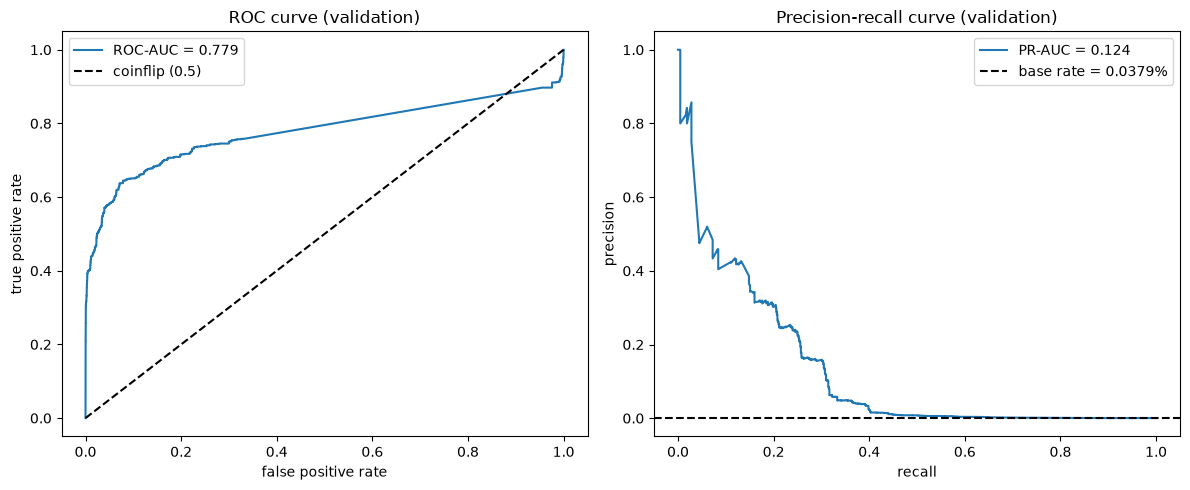

In [5]:
val_scored = _with_proba(main_model, val, MAIN_MODEL_FEATURE_COLUMNS)
fpr, tpr, _ = roc_curve(val[TARGET_COLUMN], val_scored["proba"])
roc_auc = roc_auc_score(val[TARGET_COLUMN], val_scored["proba"])

precision, recall, _ = precision_recall_curve(val[TARGET_COLUMN], val_scored["proba"])
pr_auc = average_precision_score(val[TARGET_COLUMN], val_scored["proba"])
base_rate = val[TARGET_COLUMN].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", label="coinflip (0.5)")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curve (validation)"); axes[0].legend()

axes[1].plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
axes[1].axhline(base_rate, color="k", linestyle="--", label=f"base rate = {base_rate:.4%}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curve (validation)"); axes[1].legend()
plt.tight_layout()
plt.show()


## Feature set iteration

Started with 6 features (rate-of-rise 1h/6h, rainfall 6h/24h/72h, level-vs-baseline) plus `station_id`. Adding four more hydrologically-motivated features -- rate-of-rise 12h, 7-day antecedent rainfall, peak rainfall intensity (max 1h burst within a trailing 6h window), and level-vs-24h-peak -- moved test ROC-AUC from 0.797 to 0.855 and test expected cost from £375,000 to £362,600 (see `PLAN.md` for the full before/after). The cell below reproduces that comparison on validation.


In [6]:
from xgboost import XGBClassifier

ORIGINAL_FEATURES = [
    "rate_of_rise_1h", "rate_of_rise_6h", "rainfall_6h", "rainfall_24h",
    "rainfall_72h", "level_minus_baseline", "season_sin", "season_cos", "station_id",
]

neg, pos = (train[TARGET_COLUMN] == 0).sum(), (train[TARGET_COLUMN] == 1).sum()
original_model = XGBClassifier(
    tree_method="hist", enable_categorical=True, n_estimators=600, max_depth=8,
    learning_rate=0.05, reg_lambda=1.0, min_child_weight=10,
    scale_pos_weight=neg / pos, eval_metric="aucpr", early_stopping_rounds=25,
)
original_model.fit(
    train[ORIGINAL_FEATURES], train[TARGET_COLUMN],
    eval_set=[(val[ORIGINAL_FEATURES], val[TARGET_COLUMN])], verbose=False,
)

original_proba = original_model.predict_proba(val[ORIGINAL_FEATURES])[:, 1]
expanded_proba = val_scored["proba"]

print(f"6-feature set:  val ROC-AUC = {roc_auc_score(val[TARGET_COLUMN], original_proba):.4f}   val PR-AUC = {average_precision_score(val[TARGET_COLUMN], original_proba):.4f}")
print(f"10-feature set: val ROC-AUC = {roc_auc_score(val[TARGET_COLUMN], expanded_proba):.4f}   val PR-AUC = {average_precision_score(val[TARGET_COLUMN], expanded_proba):.4f}")


6-feature set:  val ROC-AUC = 0.7781   val PR-AUC = 0.0968
10-feature set: val ROC-AUC = 0.7786   val PR-AUC = 0.1242


## What the final model actually learned (SHAP)

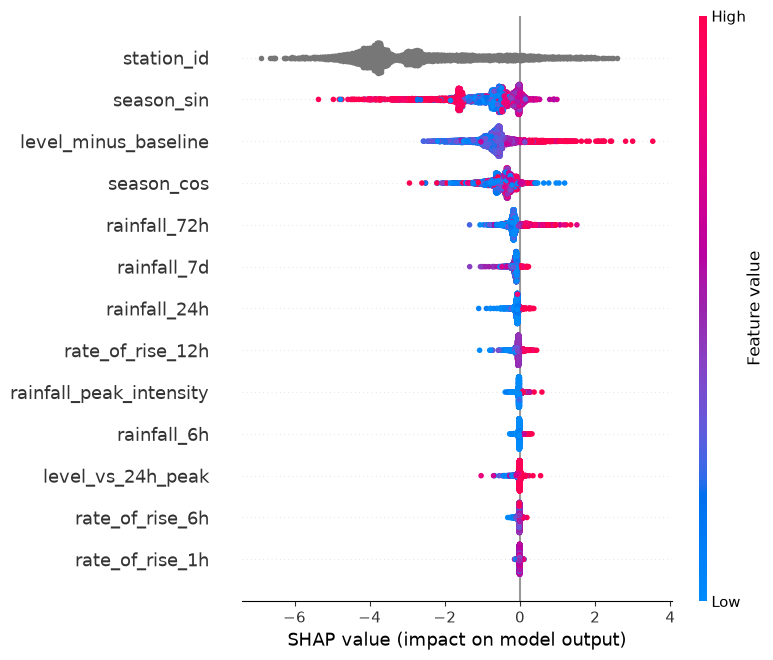

In [7]:
explainer = shap.TreeExplainer(main_model)
shap_sample = val[MAIN_MODEL_FEATURE_COLUMNS].sample(5_000, random_state=0)
shap_values = explainer(shap_sample)

shap.summary_plot(shap_values, shap_sample, show=False)
plt.tight_layout()
plt.show()


`station_id` dominates -- expected, since it lets the model learn each station's very different baseline flood-risk profile. Seasonality and the rainfall/level dynamics features follow, which is the interpretability story `/predict` surfaces per-request via `src/explain.py`.


## Final test-set numbers (touched once)

In [8]:
threshold_result = pick_operating_threshold(main_model, val, MAIN_MODEL_FEATURE_COLUMNS)
_ = evaluate(
    main_model, test, MAIN_MODEL_FEATURE_COLUMNS,
    threshold=threshold_result["best_threshold"],
    label="main XGBoost model (TEST, cost-optimal threshold)",
)
test_scored = _with_proba(main_model, test, MAIN_MODEL_FEATURE_COLUMNS)
print(f"test ROC-AUC: {roc_auc_score(test[TARGET_COLUMN], test_scored['proba']):.4f}")


cost-optimal threshold (validation): 0.960, expected cost GBP596,100


--- main XGBoost model (TEST, cost-optimal threshold) (threshold=0.9600000000000001) ---
  precision: 0.0264
  recall: 0.1778
  f1: 0.0460
  f2: 0.0829
  pr_auc: 0.0356
  confusion matrix: tn=2354723 fp=2357 fn=296 tp=64


test ROC-AUC: 0.8546
